# CardioIA Fase 2 | Parte 2: Classificador de risco com TF-IDF

Na Parte 1 as regras só reconheciam o que estava escrito no mapa. Aqui a máquina **aprende** com exemplos rotulados a separar frases de **alto risco** e **baixo risco**, como numa triagem.

Fluxo:

1. Base simulada `frases_risco.csv` (80 frases, 40 de cada classe)
2. TF-IDF transforma texto em números
3. Treino de dois modelos simples (Regressão Logística e Árvore de Decisão)
4. Avaliação: acurácia, matriz de confusão, validação cruzada
5. Testes com frases "pegadinha" para ver vieses e distorções

> Aviso: projeto acadêmico, dados simulados. Não usar para triagem real.

In [1]:
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

SEED = 42

## 1. Conhecendo a base

In [2]:
df = pd.read_csv("frases_risco.csv")
print(df.shape)
print(df["situacao"].value_counts())
df.sample(8, random_state=SEED)

(80, 2)
situacao
alto risco     40
baixo risco    40
Name: count, dtype: int64


,frase,situacao
30,o marcapasso está apitando e me sinto muito fraco,alto risco
0,sinto dor no peito e falta de ar,alto risco
22,estou tossindo sangue e com falta de ar súbita,alto risco
31,tenho dor no peito que não melhora com o reméd...,alto risco
18,o coração está batendo muito rápido e irregula...,alto risco
28,de repente fiquei sem ar e com dor no peito ao...,alto risco
10,tenho dor forte no peito quando subo um lance ...,alto risco
70,meu relógio mostrou batimento de 75 em repouso,baixo risco


Base **balanceada** (40/40). Isso importa: se tivesse 90% de baixo risco, um modelo que chuta sempre "baixo risco" teria 90% de acurácia e seria inútil.

## 2. Pré-processamento

Mesma ideia da Parte 1: minúsculas e sem acento.

**Stopwords:** removo palavras que não carregam significado (de, a, o, que...). Mas atenção: **não removo "não", "sem" e "nunca"**. Listas prontas de stopwords costumam tirar essas palavras, e em saúde isso é perigoso: "não sinto dor no peito" viraria "sinto dor peito".

In [3]:
def normalizar(texto: str) -> str:
    texto = unicodedata.normalize("NFKD", texto.lower())
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", texto).strip()

STOPWORDS = ["a", "o", "as", "os", "um", "uma", "de", "do", "da", "dos", "das", "e",
             "em", "no", "na", "nos", "nas", "que", "com", "por", "para", "pra",
             "meu", "minha", "me", "eu", "estou", "esta", "to", "ta", "sinto", "tenho",
             "tive", "ao", "se", "mas", "quando", "depois", "muito"]

df["frase_limpa"] = df["frase"].apply(normalizar)
df[["frase", "frase_limpa"]].head()

,frase,frase_limpa
0,sinto dor no peito e falta de ar,sinto dor no peito e falta de ar
1,estou com um aperto forte no peito que vai par...,estou com um aperto forte no peito que vai par...
2,desmaiei hoje de manhã no banheiro,desmaiei hoje de manha no banheiro
3,meu coração está disparado e sinto que vou des...,meu coracao esta disparado e sinto que vou des...
4,a dor no peito começou há uma hora e não passa,a dor no peito comecou ha uma hora e nao passa


## 3. TF-IDF na prática

TF-IDF dá um peso para cada palavra em cada frase:

- **TF** (frequência no termo): quantas vezes a palavra aparece na frase
- **IDF** (inverso da frequência nos documentos): palavras que aparecem em quase todas as frases valem pouco; palavras raras valem mais

Uso `ngram_range=(1, 2)` para pegar também pares de palavras. "dor peito" e "falta ar" juntos dizem mais do que "dor" sozinho.

In [4]:
vet_demo = TfidfVectorizer(stop_words=STOPWORDS, ngram_range=(1, 2))
X_demo = vet_demo.fit_transform(df["frase_limpa"])
print("Vocabulário:", len(vet_demo.vocabulary_), "termos")
print("Matriz:", X_demo.shape, "(frases x termos)")

# termos com maior peso na primeira frase
linha = pd.Series(X_demo[0].toarray()[0], index=vet_demo.get_feature_names_out())
print("\nFrase:", df.loc[0, "frase"])
linha[linha > 0].sort_values(ascending=False)

Vocabulário: 554 termos
Matriz: (80, 554) (frases x termos)

Frase: sinto dor no peito e falta de ar


peito falta    0.564287
falta          0.371110
dor peito      0.371110
falta ar       0.371110
ar             0.339619
peito          0.282057
dor            0.271138
dtype: float64

## 4. Separando treino e teste

75% para treino, 25% para teste, mantendo a proporção das classes (`stratify`).

O TF-IDF fica **dentro de um Pipeline**, então ele só aprende o vocabulário com os dados de treino. Se eu ajustasse o TF-IDF com a base inteira antes de separar, o teste "vazaria" para o treino (data leakage).

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["frase_limpa"], df["situacao"],
    test_size=0.25, stratify=df["situacao"], random_state=SEED)

print(len(X_train), "treino |", len(X_test), "teste")

def criar_pipeline(modelo):
    return Pipeline([
        ("tfidf", TfidfVectorizer(stop_words=STOPWORDS, ngram_range=(1, 2), sublinear_tf=True)),
        ("modelo", modelo),
    ])

modelos = {
    "Regressão Logística": criar_pipeline(LogisticRegression(max_iter=1000, C=5, random_state=SEED)),
    "Árvore de Decisão": criar_pipeline(DecisionTreeClassifier(max_depth=6, random_state=SEED)),
}

60 treino | 20 teste


## 5. Treino e avaliação

===== Regressão Logística =====
Acurácia no teste: 80.00%
              precision    recall  f1-score   support

  alto risco       0.88      0.70      0.78        10
 baixo risco       0.75      0.90      0.82        10

    accuracy                           0.80        20
   macro avg       0.81      0.80      0.80        20
weighted avg       0.81      0.80      0.80        20



===== Árvore de Decisão =====
Acurácia no teste: 80.00%
              precision    recall  f1-score   support

  alto risco       1.00      0.60      0.75        10
 baixo risco       0.71      1.00      0.83        10

    accuracy                           0.80        20
   macro avg       0.86      0.80      0.79        20
weighted avg       0.86      0.80      0.79        20



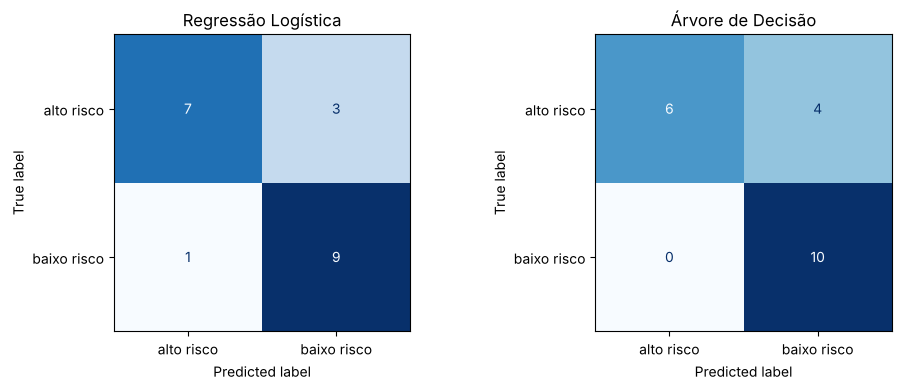

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nome, pipe) in zip(axes, modelos.items()):
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    print(f"===== {nome} =====")
    print(f"Acurácia no teste: {accuracy_score(y_test, pred):.2%}")
    print(classification_report(y_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

### Por que olhar além da acurácia?

Em triagem, os erros não pesam igual:

- **Falso negativo** (alto risco classificado como baixo): o paciente grave espera na fila. É o erro mais perigoso.
- **Falso positivo** (baixo risco classificado como alto): gasta recurso, mas ninguém corre perigo.

Por isso a métrica que mais importa aqui é o **recall da classe "alto risco"** (de todos os graves, quantos o modelo pegou).

## 6. Validação cruzada

Com só 20 frases no teste, um único sorteio pode dar sorte ou azar. A validação cruzada (5 folds) treina e testa 5 vezes em divisões diferentes e tira a média. É um número mais honesto.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for nome, pipe in modelos.items():
    scores = cross_val_score(pipe, df["frase_limpa"], df["situacao"], cv=cv, scoring="accuracy")
    print(f"{nome:20} acurácia média {scores.mean():.2%} (± {scores.std():.2%})  folds: {np.round(scores, 2)}")

Regressão Logística  acurácia média 78.75% (± 10.16%)  folds: [0.94 0.69 0.88 0.69 0.75]
Árvore de Decisão    acurácia média 68.75% (± 9.68%)  folds: [0.75 0.5  0.69 0.75 0.75]


## 7. O que o modelo aprendeu?

A Regressão Logística dá um peso para cada termo. Peso positivo puxa para uma classe, negativo para a outra. Isso deixa o modelo **explicável**, o que é essencial em saúde.

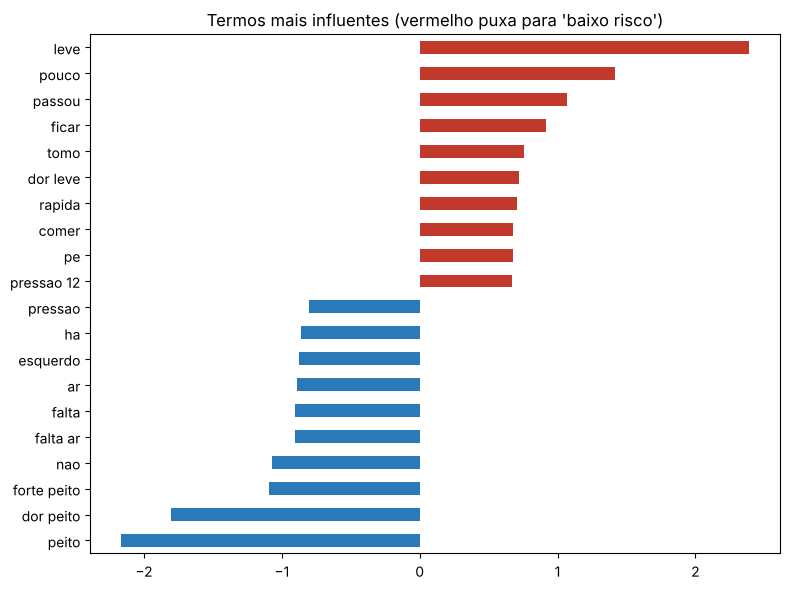

In [8]:
lr = modelos["Regressão Logística"]
lr.fit(df["frase_limpa"], df["situacao"])  # treina com tudo só para inspecionar os pesos
termos = lr.named_steps["tfidf"].get_feature_names_out()
pesos = lr.named_steps["modelo"].coef_[0]
classe_positiva = lr.named_steps["modelo"].classes_[1]

importancia = pd.Series(pesos, index=termos).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
pd.concat([importancia.head(10), importancia.tail(10)]).plot.barh(
    ax=ax, color=["#2a7ab9"] * 10 + ["#c0392b"] * 10)
ax.set_title(f"Termos mais influentes (vermelho puxa para '{classe_positiva}')")
plt.tight_layout()
plt.show()

## 8. Testando com frases novas (e algumas pegadinhas)

Aqui é onde aparecem os vieses. Escolhi frases que o modelo nunca viu, algumas de propósito difíceis.

In [9]:
def classificar_risco(frase: str, modelo=lr):
    texto = normalizar(frase)
    classe = modelo.predict([texto])[0]
    prob = modelo.predict_proba([texto])[0].max()
    return classe, prob

novas = [
    ("estou com dor no peito forte e suando frio", "alto risco"),
    ("tive um desmaio na fila do banco", "alto risco"),
    ("meu coração tá a mil e minha visão escureceu", "alto risco"),
    ("sinto uma leve dor nas costas depois do futebol", "baixo risco"),
    ("estou cansado depois de uma semana puxada", "baixo risco"),
    # pegadinhas
    ("não sinto dor no peito nem falta de ar, só vim renovar a receita", "baixo risco"),
    ("dor no peito de tanto rir no churrasco", "baixo risco"),
    ("tô meio ruim, sem forças e meio zonzo desde ontem", "alto risco"),
    ("infarto", "alto risco"),
]

linhas = []
for frase, esperado in novas:
    pred, prob = classificar_risco(frase)
    linhas.append({"frase": frase, "esperado": esperado, "previsto": pred,
                   "confiança": f"{prob:.0%}", "acertou": "sim" if pred == esperado else "NÃO"})
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(linhas)

,frase,esperado,previsto,confiança,acertou
0,estou com dor no peito forte e suando frio,alto risco,alto risco,86%,sim
1,tive um desmaio na fila do banco,alto risco,alto risco,58%,sim
2,meu coração tá a mil e minha visão escureceu,alto risco,alto risco,55%,sim
3,sinto uma leve dor nas costas depois do futebol,baixo risco,baixo risco,81%,sim
4,estou cansado depois de uma semana puxada,baixo risco,baixo risco,63%,sim
5,"não sinto dor no peito nem falta de ar, só vim renovar a receita",baixo risco,alto risco,93%,NÃO
6,dor no peito de tanto rir no churrasco,baixo risco,alto risco,91%,NÃO
7,"tô meio ruim, sem forças e meio zonzo desde ontem",alto risco,alto risco,64%,sim
8,infarto,alto risco,baixo risco,54%,NÃO


## 9. Análise de vieses e distorções

Resultados que tirei dos testes acima:

**1. Os dois modelos acertam 80% no teste, mas a validação cruzada desempata.** A Regressão Logística fica perto de 79% de média; a Árvore de Decisão cai para uns 69%. Com pouco dado, a árvore decora regras do tipo "tem a palavra X?" e generaliza pior. Por isso escolhi a Regressão Logística como modelo final.

**2. O erro que mais aparece é o perigoso.** Na matriz de confusão, os dois modelos erram mais deixando passar casos de alto risco (recall de alto risco 70% e 60%) do que o contrário. Numa triagem real isso teria que ser corrigido, por exemplo baixando o limiar de decisão para "alto risco".

**3. Viés de palavra-chave:** "dor no peito de tanto rir no churrasco" virou alto risco com mais de 90% de confiança. O modelo aprendeu que "peito" = perigo e ignora o contexto.

**4. Negação não é entendida:** "não sinto dor no peito nem falta de ar" foi classificada como alto risco. O TF-IDF vê as palavras soltas, não a relação entre elas. Manter "não" fora das stopwords ajuda, mas com 80 frases o modelo não tem exemplos suficientes para aprender isso.

**5. Vocabulário que ele nunca viu:** a frase "infarto", sozinha, saiu como baixo risco. A palavra não existe na base de treino, então para o modelo ela não significa nada. Ele não sabe medicina, só sabe estatística das frases que recebeu.

**6. Confiança baixa em frases coloquiais:** "tô meio ruim, sem forças e meio zonzo" acertou, mas com só 64%. Jeitos diferentes de falar (gírias, regionalismos) deixam o modelo inseguro.

**Como melhorar:** mais frases (centenas, não dezenas), exemplos com negação e contexto, rótulos revisados por profissional de saúde, e combinar com a Parte 1 (as regras podem reforçar termos como "infarto" que o modelo não conhece).

## 10. Governança de dados (reflexão)

- **Quem rotulou:** eu, sem formação médica. O rótulo reflete minha percepção de gravidade, não um protocolo clínico (como o Manchester, usado em pronto-socorro).
- **Representatividade:** frases escritas por uma pessoa só, com um jeito de falar. Paciente idoso, de outra região, com baixa escolaridade ou que escreve com erro pode ser mal classificado.
- **Sem dados demográficos:** isso evita viés por sexo ou idade dentro do modelo, mas também esconde um problema real. Mulheres costumam relatar infarto com sintomas menos "clássicos" (cansaço, enjoo, dor nas costas). Uma base cheia de "dor no peito irradiando pro braço" tende a ensinar o modelo a reconhecer o infarto típico e deixar passar o atípico.
- **Uso responsável:** um sistema desses só faz sentido como **apoio** a um profissional, com o modelo sempre errando para o lado do "alto risco" quando estiver em dúvida, e com registro das decisões para auditoria (LGPD e Cap. 7 da fase).